# Variante B: previsão rolling de um passo

Na variante B cada previsão é de um passo, e o valor real chega logo depois. Os parâmetros ficam congelados:

1. prever `t+1` usando só o que foi observado até `t`;
2. observar `y[t+1]`;
3. atualizar a janela de resíduos com o erro da base naquele instante;
4. avançar, **sem chamar `fit`**.

A seleção usa o erro de um passo na validação. A seleção dinâmica de corretores só é permitida nesta variante.

In [1]:
import autohybts

print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc2


## 1. Experimento na variante B

In [2]:
from autohybts import AutoHybridExperiment
from autohybts.datasets import get_data

y = get_data("synthetic_daily")
exp = AutoHybridExperiment(fh=1, variant="B", test_size=28, session_id=42).fit(y)
result = exp.compare_models()
result.leaderboard

,name,model,family,strategy,base,corrector,residual_source,window,alpha,mean_rank,...,MAE,RMSE,sMAPE,coverage,n_units,n_failed,n_skipped,fit_seconds,predict_seconds,is_champion
candidate_id,,,,,,,,,,,,,,,,,,,,,
f197a4a852eefc42b77e9d063dff3c84cf252feda2deb62c878faf84713a4449,arima,arima,statistical,standalone,arima,NaN,NaN,NaN,NaN,1.0,...,0.883120,0.883120,0.012429,1.0,7,0,0,16.643486,0.012792,True
dcc94aa07bedae7630b1f38c2570937852793c439f560bfd9098cbedf9650690,arima-linear,"arima + linear [w=7, alpha=0.5, historical_oof...",residual,residual_additive,arima,linear,historical_oof_1step,7.0,0.5,2.0,...,0.885318,0.885318,0.012459,1.0,7,0,0,4.903926,0.012789,False
0ec158f3b6ec517f088da25b7c2f75c10bfe627d7bf5437f0622b8ff36cca85a,arima-linear,"arima + linear [w=7, alpha=0.5, in_sample]",residual,residual_additive,arima,linear,in_sample,7.0,0.5,3.0,...,0.886370,0.886370,0.012471,1.0,7,0,0,0.262579,0.013400,False
50c3b10b84c20c32b6b898008596592cb4f651f3f73110b54230461381267f3e,arima-linear,"arima + linear [w=7, alpha=1.0, historical_oof...",residual,residual_additive,arima,linear,historical_oof_1step,7.0,1.0,4.0,...,0.891898,0.891898,0.012552,1.0,7,0,0,0.383705,0.014258,False
c51a658f4db43de6316044da15702a7d11e9e319df05363c4688b9ba00547929,mlp,mlp(lags=7),neural,standalone,mlp,NaN,NaN,NaN,NaN,5.0,...,0.892754,0.892754,0.012454,1.0,7,0,0,0.654276,0.002061,False
4a92d125bd10f30ce4cdf0fc07e114c1e0d07bbd03ca06dd5a8c04c2781bfd4b,svm,svm(lags=7),kernel,standalone,svm,NaN,NaN,NaN,NaN,6.0,...,0.926790,0.926790,0.013126,1.0,7,0,0,0.102579,0.002965,False
c05fbfc4191206898692474cb6edb6c95948dcd38fd203e4d6be47b604035efe,linear,linear(lags=7),linear,standalone,linear,NaN,NaN,NaN,NaN,7.0,...,0.939771,0.939771,0.013160,1.0,7,0,0,1.025291,0.001306,False
3e1cf077f43789200b40b04ab5b6098eb7f916132b72ca9bbd6f6f8eba5f3d02,arima-linear,"arima + linear [w=7, alpha=0.5, historical_oof...",residual,residual_additive,arima,linear,historical_oof_multistep,7.0,0.5,8.0,...,0.958163,0.958163,0.013517,1.0,7,0,0,9.948506,0.012775,False
1984f459ddd73973f8dee0312933d0c5d4a4ae9ff5e3e8a400a30bd0b87baff5,linear-linear,"linear(lags=7) + linear [w=7, alpha=0.5, histo...",residual,residual_additive,linear,linear,historical_oof_1step,7.0,0.5,9.0,...,1.002286,1.002286,0.013990,1.0,7,0,0,0.509810,0.002312,False


## 2. Finalizar e avaliar no teste selado

In [3]:
final = exp.finalize_model(result.best)
exp.evaluate_external(final).metrics

,MASE,MAE,RMSE,sMAPE
model,,,,
arima,0.532694,0.83562,1.022446,0.011846


## 3. Streaming em produção

O mesmo modelo, recebendo observações novas uma a uma. Aqui simulamos a chegada dos dados com as últimas 28 observações da série.

In [4]:
import pandas as pd

stream = final.stream()
rows = []
for timestamp, actual in y.iloc[-28:].items():
    ticket = stream.predict_next()
    rows.append({"timestamp": timestamp, "y_pred": ticket.prediction, "y_true": actual})
    stream.observe(actual)  # só agora o valor real fica disponível

stream_log = pd.DataFrame(rows).set_index("timestamp")
stream_log["abs_error"] = (stream_log["y_true"] - stream_log["y_pred"]).abs()
stream_log

,y_pred,y_true,abs_error
timestamp,,,
2025-12-03,73.163889,72.429605,0.734284
2025-12-04,70.867025,71.246072,0.379047
2025-12-05,68.793807,70.065617,1.271810
2025-12-06,68.582059,67.422345,1.159713
2025-12-07,68.022263,67.361921,0.660342
2025-12-08,69.636127,70.737740,1.101613
2025-12-09,73.005390,73.033376,0.027986
2025-12-10,73.587046,74.455786,0.868740
2025-12-11,72.897800,72.770706,0.127095


## 4. Previsto × observado

Cada ponto laranja foi previsto antes de o valor preto ser observado; o modelo só viu o passado de cada ponto.

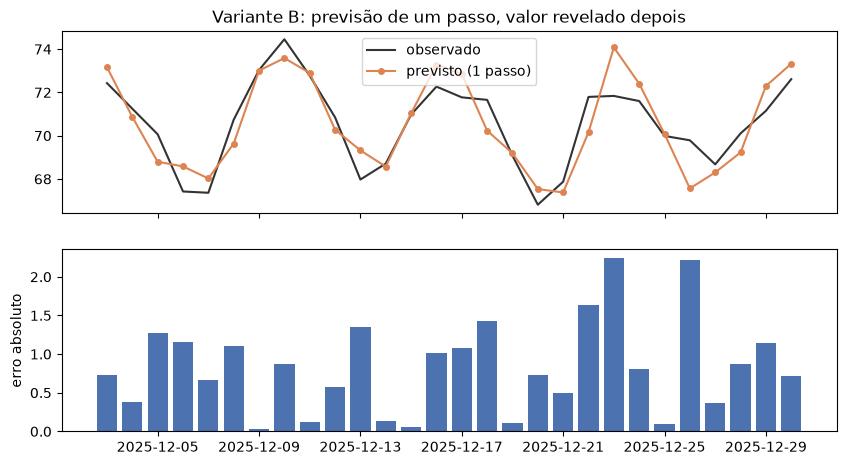

In [5]:
import matplotlib.pyplot as plt

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True)
top.plot(stream_log.index, stream_log["y_true"], color="#333333", label="observado")
top.plot(
    stream_log.index,
    stream_log["y_pred"],
    "o-",
    color="#DD8452",
    markersize=4,
    label="previsto (1 passo)",
)
top.set_title("Variante B: previsão de um passo, valor revelado depois")
top.legend()
bottom.bar(stream_log.index, stream_log["abs_error"], color="#4C72B0")
bottom.set_ylabel("erro absoluto")
plt.show()

## 5. Base e correção a cada passo

O campeão aqui é um modelo individual, sem corretor. Para ver o que a variante B faz num híbrido, o `arima-linear` é avaliado nas mesmas origens, finalizado e transmitido pelos mesmos 28 dias. Cada `ForecastTicket` traz a previsão da base e a correção; o resíduo observado `y − b` entra na janela do corretor só depois da observação.

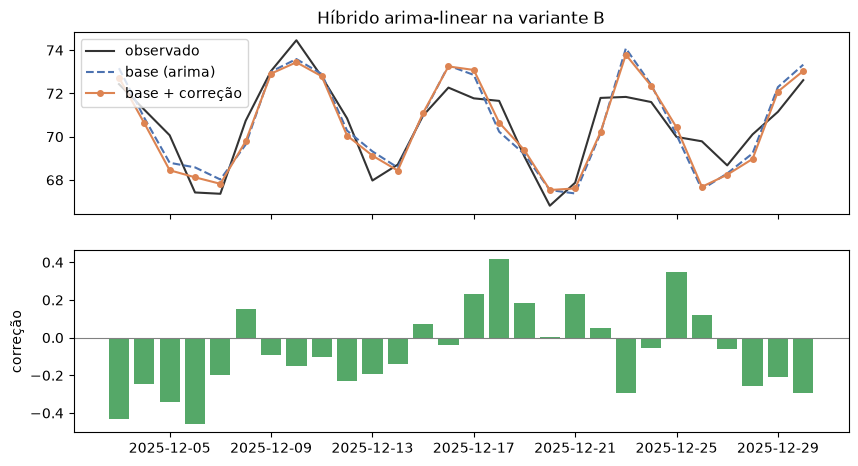

base               0.836
base + correção    0.803
Name: MAE nos 28 dias, dtype: float64

In [6]:
hybrid = exp.create_hybrid("arima", "linear")
hybrid_stream = exp.finalize_model(hybrid).stream()
steps = []
for timestamp, actual in y.iloc[-28:].items():
    ticket = hybrid_stream.predict_next()
    steps.append(
        {
            "timestamp": timestamp,
            "base": ticket.base_prediction,
            "correction": ticket.correction,
            "y_pred": ticket.prediction,
            "y_true": actual,
        }
    )
    hybrid_stream.observe(actual)
steps = pd.DataFrame(steps).set_index("timestamp")

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True)
top.plot(steps.index, steps["y_true"], color="#333333", label="observado")
top.plot(steps.index, steps["base"], "--", color="#4C72B0", label="base (arima)")
top.plot(steps.index, steps["y_pred"], "o-", color="#DD8452", markersize=4, label="base + correção")
top.set_title("Híbrido arima-linear na variante B")
top.legend()
bottom.bar(steps.index, steps["correction"], color="#55A868")
bottom.axhline(0, color="gray", linewidth=0.8)
bottom.set_ylabel("correção")
plt.show()
errors = {
    "base": (steps["y_true"] - steps["base"]).abs().mean(),
    "base + correção": (steps["y_true"] - steps["y_pred"]).abs().mean(),
}
pd.Series(errors, name="MAE nos 28 dias").round(3)

## 6. Variantes A e B no mesmo trecho

A mesma estrutura campeã, agora na variante A: finalizada no mesmo histórico, ela prevê os 28 dias de uma vez a partir do fim do treino, sem ver nenhum valor desse trecho. Na variante B, cada dia foi previsto com os dias anteriores já observados. É a diferença descrita na página "Variantes A e B" do guia do usuário.

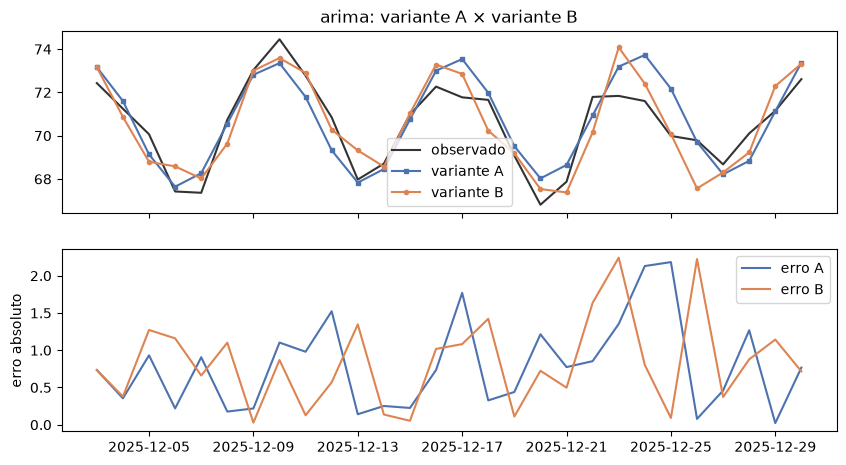

A (28 passos)    0.791
B (1 passo)      0.836
Name: MAE, dtype: float64

In [7]:
from dataclasses import replace

exp_a = AutoHybridExperiment(fh=28, test_size=28, session_id=42).fit(y)
final_a = exp_a.finalize_model(replace(result.best, variant="A"))  # mesma estrutura, variante A
forecast_a = exp_a.predict_model(final_a).predictions["y_pred"]

comparison = pd.DataFrame(
    {
        "y_true": stream_log["y_true"],
        "A (28 passos)": forecast_a.to_numpy(),
        "B (1 passo)": stream_log["y_pred"],
    }
)
error_a = (comparison["y_true"] - comparison["A (28 passos)"]).abs()
error_b = (comparison["y_true"] - comparison["B (1 passo)"]).abs()

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True)
top.plot(comparison.index, comparison["y_true"], color="#333333", label="observado")
top.plot(
    comparison.index,
    comparison["A (28 passos)"],
    "s-",
    color="#4C72B0",
    markersize=3,
    label="variante A",
)
top.plot(
    comparison.index,
    comparison["B (1 passo)"],
    "o-",
    color="#DD8452",
    markersize=3,
    label="variante B",
)
top.set_title(f"{result.best.label}: variante A × variante B")
top.legend()
bottom.plot(comparison.index, error_a, color="#4C72B0", label="erro A")
bottom.plot(comparison.index, error_b, color="#DD8452", label="erro B")
bottom.set_ylabel("erro absoluto")
bottom.legend()
plt.show()
pd.Series({"A (28 passos)": error_a.mean(), "B (1 passo)": error_b.mean()}, name="MAE").round(3)

## 7. Leitura

* **Streaming.** O campeão (`arima`) previu os 28 dias um passo por vez, sem reajuste, com MAE 0,836 — o mesmo valor da avaliação externa, que na variante B também é feita em rolagem de um passo.
* **Base e correção.** No híbrido `arima-linear`, a correção ficou abaixo de 0,5 em valor absoluto em todos os dias e baixou o MAE dos 28 dias de 0,836 (só a base) para 0,803; cada correção usou só resíduos já observados.
* **A × B.** Neste trecho a variante A teve MAE menor (0,791 contra 0,836). O `arima` escolhido projeta bem o ciclo semanal e a tendência 28 dias à frente, e o erro de A não cresceu com o horizonte; a previsão de um passo reage ao último valor, que carrega o ruído AR(1). A variante B não garante menor erro: ela serve quando cada valor chega antes da próxima previsão. Em séries com componente pouco previsível, o erro de A tende a crescer com o horizonte.
* **Limites.** Um único trecho de 28 dias de uma série sintética; a comparação ilustra a mecânica, não estima qual variante erra menos em geral.